# The TED Spread After LIBOR
### Rebuilding a banking-stress indicator, 1986–2026

$$\text{TED} = \text{3-month interbank rate} - \text{3-month Treasury bill rate}$$

The TED spread is the premium banks pay over the US government to borrow unsecured for three months. It widens when markets doubt bank solvency (the interbank leg rises) or rush into safe assets (the T-bill leg falls), which makes it a classic gauge of banking-system stress.

Its traditional interbank leg, 3-month USD LIBOR, is no longer published. This notebook:

1. rebuilds 40 years of the spread by reconstructing LIBOR from FRED's `TEDRATE` series up to January 2022 and splicing in **AMERIBOR Term-90** after it,
2. validates the splice on the period where both series exist, and
3. reads the result against four stress episodes: the 1987 crash, the Global Financial Crisis, COVID-19 and the 2023 Silicon Valley Bank failure.

**Key findings**

- The spread peaked at **458 bp on 2008-10-10**, in the weeks after Lehman Brothers' collapse.
- In all four episodes the **T-bill leg moved more than the interbank leg**: widening came mainly from a flight to quality into T-bills. During the GFC and COVID both legs actually fell, as Fed rate cuts pulled rates down while T-bills fell much further.
- AMERIBOR tracks reconstructed LIBOR closely where they overlap (**168 days, correlation 0.92, mean gap −1.0 bp**) and still flagged the SVB failure (**+58 bp in 7 trading days**), though with a lag.

## 1. Data sourcing and alignment

T-bill rates come from FRED (`DTB3`). LIBOR is reconstructed as `TEDRATE + DTB3` up to 2022-01-21, the last date FRED published `TEDRATE`; AMERIBOR Term-90 takes over from 2022-01-24. Both legs are then aligned on common trading days.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style

style.use("dark_background")

# Government leg: 3-month T-bill (FRED: DTB3)
dtb3 = (
    pd.read_csv("data/DTB3.csv", index_col=0, parse_dates=True)["DTB3"]
    .dropna()
)
# Interbank leg, part 1: 3-month USD LIBOR (FRED: TEDRATE + DTB3)
tedrate = (
    pd.read_csv("data/TEDRATE.csv", index_col=0, parse_dates=True)["TEDRATE"]
    .dropna()
)
usd_libor = (tedrate + dtb3).round(2).dropna().rename("USD LIBOR")
# Interbank leg, part 2: AMERIBOR Term-90 (post-LIBOR substitute, via macrotrends)
ambor90t = (
    pd.read_csv("data/AMBOR90T.csv", index_col=0, parse_dates=True,
                date_format="%m/%d/%Y")["Value"]
    .rename("AMBOR90T")
)
ambor90t = ambor90t[ambor90t.index.dayofweek < 5]   # drop weekend carry-forward rows
# Splice: LIBOR to 2022-01-21, AMERIBOR from 2022-01-24
interbank_leg = pd.concat([usd_libor, ambor90t.loc["2022-01-24":]])
# Align both legs on common dates and compute the spread
df = pd.concat([interbank_leg, dtb3], axis=1,
               keys=["3-month Interbank Lending Rate", "3-month Treasury Bill Rate"],
               sort=True).dropna()
df["TED (bp)"] = ((df["3-month Interbank Lending Rate"] - df["3-month Treasury Bill Rate"]) * 100).round(1)

df

,3-month Interbank Lending Rate,3-month Treasury Bill Rate,TED (bp)
1986-01-02,8.00000,7.10,90.0
1986-01-03,8.06000,7.07,99.0
1986-01-06,8.13000,7.06,107.0
1986-01-07,8.12000,7.03,109.0
1986-01-08,8.00000,7.17,83.0
...,...,...,...
2026-10-08,4.26398,4.05,21.4
2026-10-09,4.26415,4.06,20.4
2026-10-13,4.27397,4.09,18.4
2026-10-14,4.28322,4.10,18.3


## 2. Validating the splice

Between May 2021 and January 2022 both reconstructed LIBOR and AMERIBOR are available, so the substitute can be tested against the series it replaces.

Overlap: 2021-05-17 to 2022-01-21, n = 168
Correlation:      0.921
Mean gap:         -1.0 bp
Mean |gap|:       1.5 bp
Max |gap|:        5.4 bp


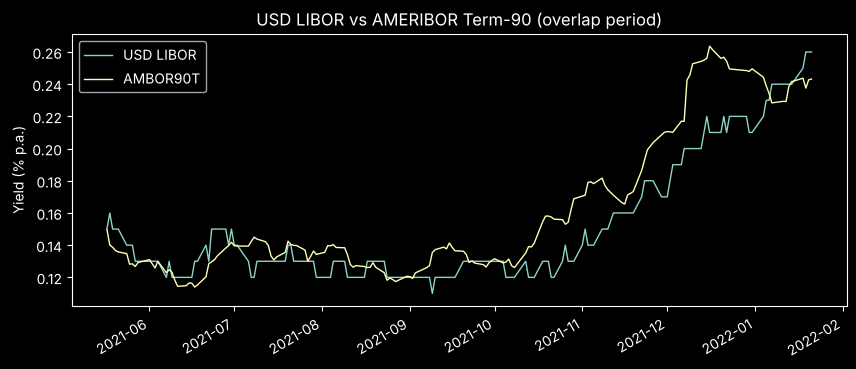

In [2]:
# Validation: reconstructed LIBOR vs AMERIBOR on overlapping dates
overlap = pd.concat([usd_libor, ambor90t], axis=1, sort=True).dropna()
gap_bp = (overlap["USD LIBOR"] - overlap["AMBOR90T"]) * 100

print(f"Overlap: {overlap.index.min().date()} to {overlap.index.max().date()}, n = {len(overlap)}")
print(f"Correlation:      {overlap.corr().iloc[0, 1]:.3f}")
print(f"Mean gap:         {gap_bp.mean():.1f} bp")
print(f"Mean |gap|:       {gap_bp.abs().mean():.1f} bp")
print(f"Max |gap|:        {gap_bp.abs().max():.1f} bp")

overlap.plot(figsize=(10, 4), title="USD LIBOR vs AMERIBOR Term-90 (overlap period)",
             ylabel="Yield (% p.a.)", lw=1)
plt.show()

## 3. The two legs and the spread

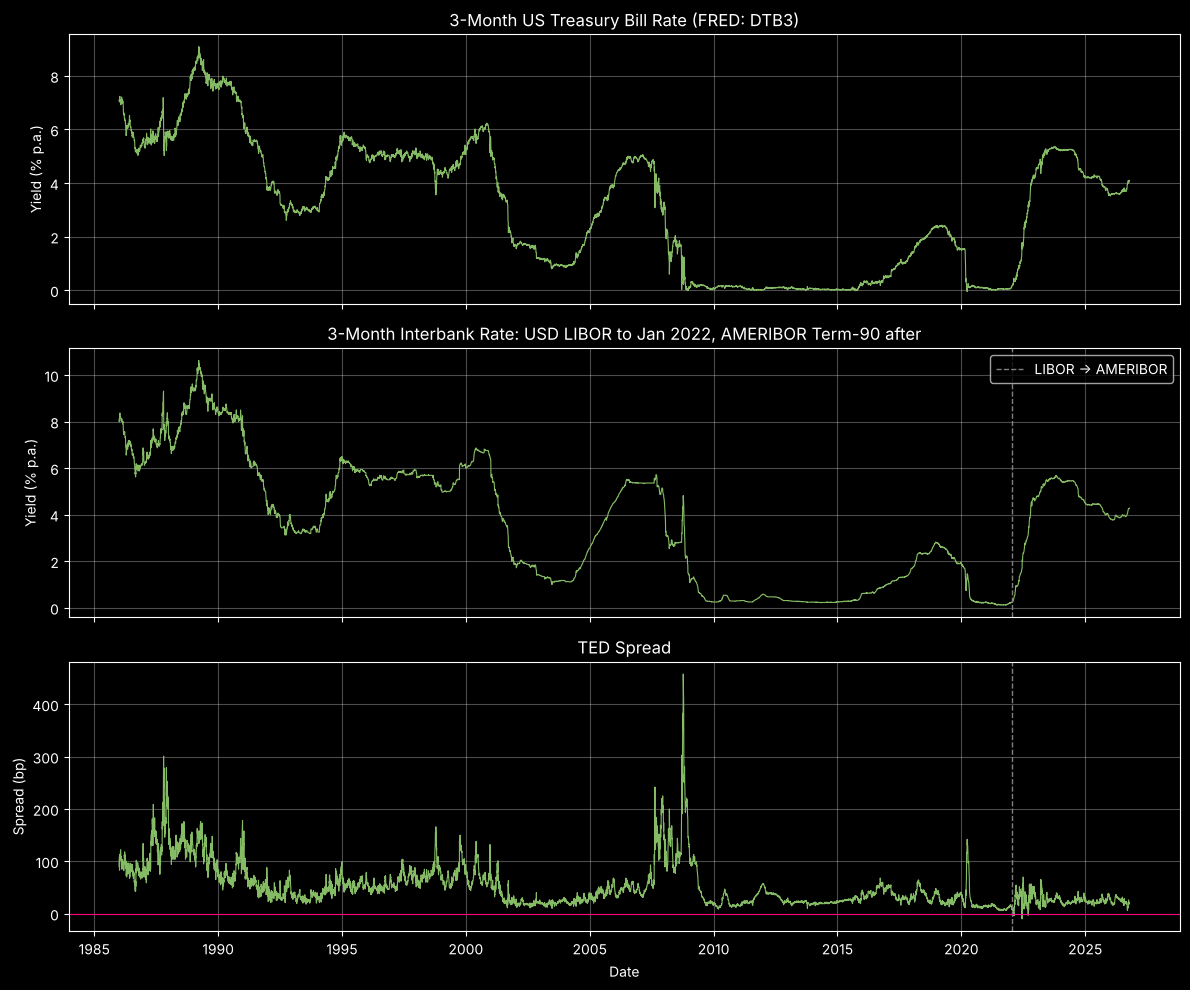

In [3]:
SPLICE = pd.Timestamp("2022-01-24")

panels = [
    ("3-month Treasury Bill Rate",
     "3-Month US Treasury Bill Rate (FRED: DTB3)", "Yield (% p.a.)"),
    ("3-month Interbank Lending Rate",
     "3-Month Interbank Rate: USD LIBOR to Jan 2022, AMERIBOR Term-90 after",
     "Yield (% p.a.)"),
    ("TED (bp)", "TED Spread", "Spread (bp)"),
]


def make_plots():
    Fig, Axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    for Ax, (col, title, ylabel) in zip(Axes, panels):
        Ax.plot(df.index, df[col], lw=0.8, color='#85BB65')
        Ax.set(title=title, ylabel=ylabel)
        Ax.grid(alpha=0.3)

    for Ax in Axes[1:]:
        Ax.axvline(SPLICE, color="grey", ls="--", lw=1, label="LIBOR → AMERIBOR")
    Axes[1].legend(loc="upper right")
    Axes[2].axhline(0, color="#FF007F", lw=0.8)
    Axes[-1].set_xlabel("Date")

    Fig.tight_layout()
    return Fig, Axes


fig, axes = make_plots()
plt.show()

## 4. Stress episodes

Each episode is shaded on all three panels. The printed numbers are the change in each leg (bp) from the start of the window to the date the TED spread peaked inside it.

1987 crash 1987-10-01 -> 1987-10-20
3-month Interbank Lending Rate     62.0
3-month Treasury Bill Rate        -77.0
TED (bp)                          139.0
dtype: float64 

GFC 2007-08-01 -> 2008-10-10
3-month Interbank Lending Rate    -54.0
3-month Treasury Bill Rate       -451.0
TED (bp)                          397.0
dtype: float64 

COVID 2020-02-20 -> 2020-03-26
3-month Interbank Lending Rate    -31.0
3-month Treasury Bill Rate       -160.0
TED (bp)                          129.0
dtype: float64 

SVB failure 2023-03-08 -> 2023-03-17
3-month Interbank Lending Rate     5.0
3-month Treasury Bill Rate       -53.0
TED (bp)                          58.0
dtype: float64 



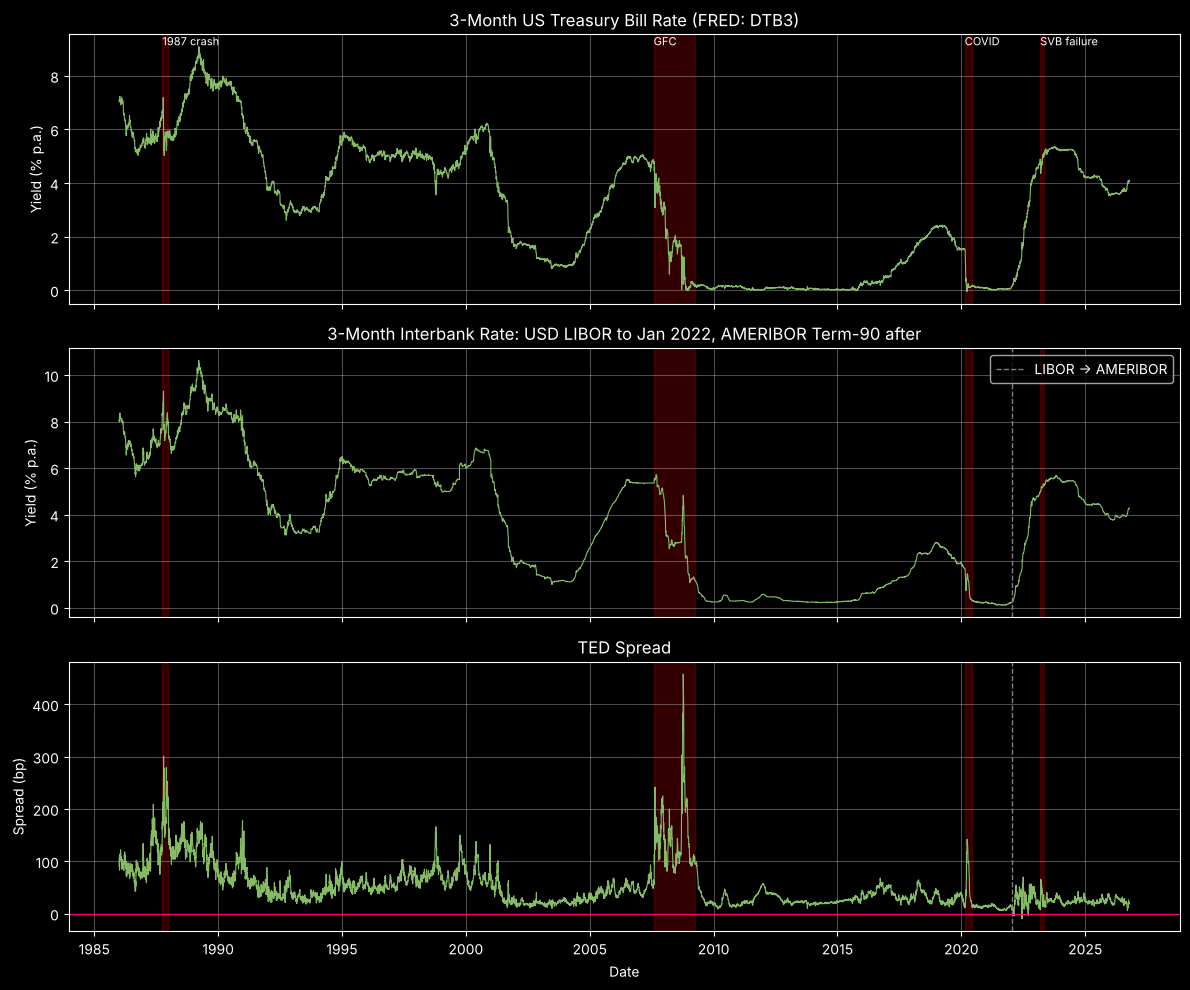

In [4]:
events = [
    ("1987 crash", "1987-10-01", "1987-12-31"),
    ("GFC", "2007-08-01", "2009-03-31"),
    ("COVID", "2020-02-20", "2020-05-31"),
    ("SVB failure", "2023-03-08", "2023-04-28"),
]
for label, start, end in events:
    w = df.loc[start:end]
    peak = w["TED (bp)"].idxmax()
    print(label, w.index[0].date(), "->", peak.date())
    print(((w.loc[peak] - w.iloc[0]) * [100, 100, 1]).round(0), "\n")

fig, axes = make_plots()
for label, start, end in events:
    for ax in axes:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.2, color="red")
    axes[0].text(pd.Timestamp(start), axes[0].get_ylim()[1], label, va="top", fontsize=8)
plt.show()

**1. October 1987 stock market crash (1987-10-01 → peak 1987-10-20).** The T-bill leg fell by about 77 bp while the interbank leg rose by about 62 bp. As global stock markets collapsed, investors panicked and fled to the safest, most liquid asset, T-bills, pushing their prices up and yields down (flight to quality). At the same time, margin calls left banks desperately short of cash, pushing up the rate at which they would lend to each other. Both legs moved in the widening direction, so the TED spread widened by about 139 bp, visible as the sharp 1987 spike in the combined-spread plot.

**2. Global Financial Crisis (2007-08-01 → peak 2008-10-10).** Both legs fell: the interbank leg by about 54 bp and the T-bill leg by about 451 bp. The Federal Reserve cut policy rates aggressively, which pulled both legs down, but an unprecedented flight to safety drove T-bill yields toward zero, far below the interbank rate. Severe systemic distress and counterparty fear after Lehman Brothers' collapse kept interbank rates high relative to T-bills. The net effect was a widening of about 397 bp, peaking at 458 bp on 2008-10-10, the largest spike in the combined-spread plot.

**3. COVID-19 market shock (2020-02-20 → peak 2020-03-26).** Both legs fell: the interbank leg by about 31 bp and the T-bill leg by about 160 bp. The Federal Reserve's emergency cuts to near zero pulled both legs down, but massive global uncertainty triggered a flight to safety that drove T-bill yields down much further. At the same time, a sudden and severe liquidity crunch in the banking sector kept interbank rates elevated relative to T-bills. The net effect was a widening of about 129 bp, visible as the sharp March 2020 spike in the combined-spread plot.

**4. Silicon Valley Bank failure (2023-03-08 → peak 2023-03-17).** This is the first major banking-stress episode after the switch to AMERIBOR, so it tests whether the substitute still detects bank stress. Over these seven trading days the T-bill leg fell by about 53 bp (4.89% → 4.36%) while the interbank leg barely moved (+5 bp). SVB's collapse, driven by unrealised losses on long-dated bonds and a run on uninsured deposits, triggered a flight to quality into T-bills, reinforced by markets pricing a pause in Fed hikes. The interbank leg reacted later, rising to 5.20% by 2023-03-24, consistent with AMERIBOR's lag as a transaction-window rate; part of that rise also reflects the Fed's 25 bp hike on 2023-03-22, so not all of it is credit stress. The net effect was a widening of about 58 bp (7.3 bp → 65.5 bp), roughly three standard deviations above the 2022–23 average of 28.9 bp, visible as a clear spike after the splice line — evidence that an AMERIBOR-based TED spread still captures banking-sector stress, albeit with a delay.

## 5. Data sources and the LIBOR substitution

### Sources

- **Government leg:** 3-Month Treasury Bill, secondary market rate, daily — FRED series `DTB3` (Federal Reserve Board H.15), 1986-01-02 to 2026-10-15.
- **Interbank leg to 2022-01-21:** 3-month USD LIBOR, reconstructed as `TEDRATE + DTB3` on matching dates (FRED series `TEDRATE`, daily, ends 2022-01-21), rounded to 2 dp.
- **Interbank leg from 2022-01-24:** AMERIBOR Term-90 (American Financial Exchange), series `AMBOR90T`, downloaded from macrotrends.net; weekend carry-forward rows removed.
- **Alignment:** both legs joined on common trading days, days missing either leg dropped (10,035 observations). Spread = interbank − T-bill, in bp.

### Why AMERIBOR

USD LIBOR requires a substitute after January 2022 because it was discontinued: FRED stopped publishing it in January 2022, and USD LIBOR panels ended in June 2023. A suitable substitute must be unsecured, so that it carries bank credit risk the way LIBOR did. SOFR does not qualify, because it is a secured overnight rate backed by Treasury securities. AMERIBOR Term-90 is unsecured, has the same 3-month tenor, and is based on the actual funding costs of US banks, so it reflects bank credit risk in the way LIBOR did.

On the 168 trading days where both series exist (2021-05-17 to 2022-01-21), AMERIBOR tracks reconstructed LIBOR closely: correlation 0.92, mean gap −1.0 bp, largest gap 5.4 bp. That overlap is a calm, near-zero-rate period, so it validates the *level* of the substitute rather than its behaviour under stress; the SVB episode above is the stress test.

### Limitations

AMERIBOR Term-90 is calculated from bank funding transactions over a window of recent days, so it reacts with a lag. During the rapid rate hikes of 2022 this lag produced a slightly negative TED spread on 5 days (lowest −10.1 bp), and during the SVB episode the interbank leg moved several days after T-bills.

### Reproducing

Place the three CSVs in `data/`: `DTB3.csv` and `TEDRATE.csv` from FRED, and `AMBOR90T.csv` from macrotrends (AMERIBOR Term-90). The data files are not included in this repository because LIBOR-derived and AMERIBOR data are licensed.